# Task 1. Осциллятор Ван-дер-Поля

Исследую уравнение

$$x''-\mu(1-x^2)x'+x=0,\qquad \mu>0.$$

Найду равновесие, проверю его устойчивость и посмотрю, как ведут себя решения при разных начальных условиях.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## 1. Система первого порядка

Пусть $y=x'$. Тогда

$$
\begin{cases}
x'=y,\\
y'=\mu(1-x^2)y-x.
\end{cases}
$$

In [2]:
def vdp(t, state, mu):
    x, y = state
    return [y, mu * (1 - x**2) * y - x]

## 2. Положения равновесия

Решаю систему $f(x,y)=0$, $g(x,y)=0$ с помощью SymPy.

In [3]:
x, y, mu = sp.symbols('x y mu')
f = y
g = mu * (1 - x**2) * y - x
points = sp.solve((f, g), (x, y))
print('Положения равновесия:', points)

Положения равновесия: [(0, 0)]


Получилось **одно равновесие**: $(0,0)$. При $\mu>0$ его количество не меняется.

## 3. Линеаризация

Найду матрицу Якоби и собственные значения в равновесии при $\mu=1$.

In [4]:
J = sp.Matrix([f, g]).jacobian([x, y])
A = J.subs({x: 0, y: 0, mu: 1})
print('Матрица Якоби:')
display(J)
print('В точке (0, 0) при mu = 1:')
display(A)
print('Собственные значения:')
display(A.eigenvals())

Матрица Якоби:


Matrix([
[            0,             1],
[-2*mu*x*y - 1, mu*(1 - x**2)]])

В точке (0, 0) при mu = 1:


Matrix([
[ 0, 1],
[-1, 1]])

Собственные значения:


{1/2 - sqrt(3)*I/2: 1, 1/2 + sqrt(3)*I/2: 1}

Собственные значения равны $\lambda_{1,2}=(1\pm i\sqrt{3})/2$. Их действительная часть положительная, значит, **равновесие неустойчиво** (неустойчивый фокус).

Предполагаю, что решения будут выходить на колебания с постоянной амплитудой.

## 4. Первое численное решение

Беру $\mu=1$, $x(0)=0.1$, $y(0)=0$ и решаю на $[0,30]$.

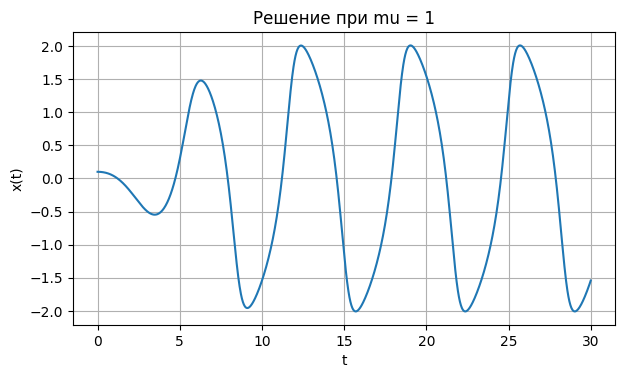

Максимум |x| при t >= 20: 2.0086


In [5]:
t = np.linspace(0, 30, 1501)
sol = solve_ivp(vdp, (0, 30), [0.1, 0], args=(1,), t_eval=t,
                rtol=1e-9, atol=1e-11)
assert sol.success

plt.figure(figsize=(7, 3.8))
plt.plot(sol.t, sol.y[0])
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Решение при mu = 1')
plt.grid(True)
plt.show()

print('Максимум |x| при t >= 20:', round(np.max(np.abs(sol.y[0, sol.t >= 20])), 4))

Колебания сначала усиливаются, но амплитуда не растёт бесконечно: после переходного участка она становится примерно постоянной, около 2. Затухания тоже нет.

## 5. Фазовая траектория

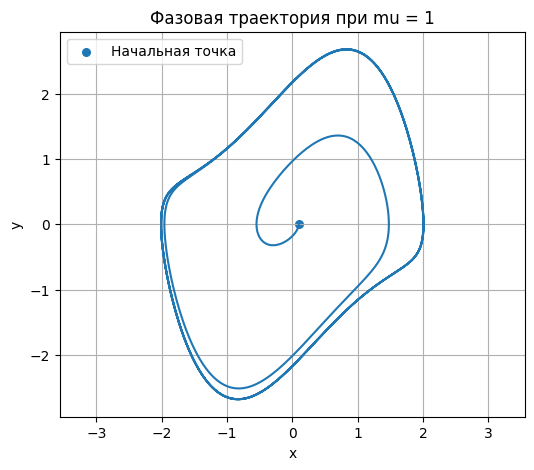

In [6]:
plt.figure(figsize=(6, 5))
plt.plot(sol.y[0], sol.y[1])
plt.scatter([0.1], [0], s=30, label='Начальная точка')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Фазовая траектория при mu = 1')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

Сначала траектория раскручивается от начала координат, затем идёт почти по одной замкнутой кривой.

## 6. Разные начальные условия

Сравню четыре точки: $(0.1,0)$, $(1,0)$, $(3,0)$ и $(4,2)$.

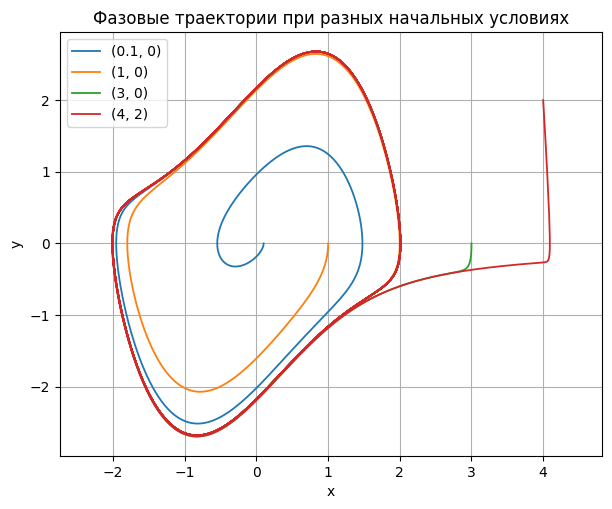

Максимум |x| на участке t >= 30:
(0.1, 0) : 2.0086
(1, 0) : 2.0086
(3, 0) : 2.0086
(4, 2) : 2.0086


In [7]:
starts = [(0.1, 0), (1, 0), (3, 0), (4, 2)]
t = np.linspace(0, 45, 2251)
curves = []

plt.figure(figsize=(7, 5.5))
for a in starts:
    s = solve_ivp(vdp, (0, 45), a, args=(1,), t_eval=t,
                  rtol=1e-9, atol=1e-11)
    assert s.success
    curves.append(s)
    plt.plot(s.y[0], s.y[1], label=str(a), linewidth=1.3)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Фазовые траектории при разных начальных условиях')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

print('Максимум |x| на участке t >= 30:')
for a, s in zip(starts, curves):
    print(a, ':', round(np.max(np.abs(s.y[0, s.t >= 30])), 4))

Из точек рядом с нулём траектории постепенно раскручиваются наружу. Из дальних точек они подходят к замкнутой кривой снаружи. В итоге все четыре решения выходят примерно на один и тот же цикл.

## 7. Предельный цикл

Для наглядности оставлю на графике только последние участки тех же решений.

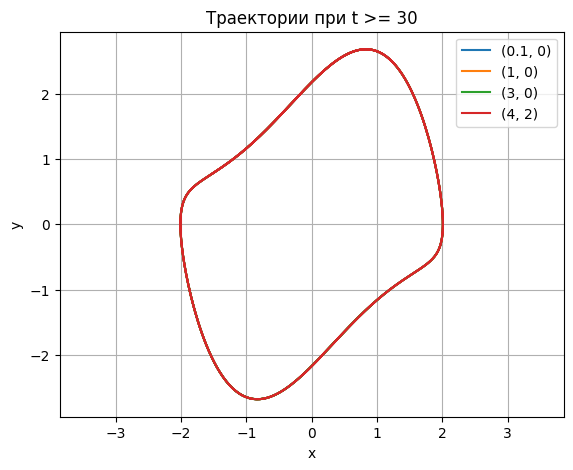

In [8]:
plt.figure(figsize=(6.5, 5))
for a, s in zip(starts, curves):
    k = s.t >= 30
    plt.plot(s.y[0, k], s.y[1, k], label=str(a))

plt.xlabel('x')
plt.ylabel('y')
plt.title('Траектории при t >= 30')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

Последние участки траекторий почти совпадают. Это похоже на **устойчивый предельный цикл**: к нему подходят решения с разных начальных точек. Но по одним графикам строго доказать его существование нельзя.

## 9. Дополнительное задание

Возьму ещё три начальные точки: $(-0.2,0)$, $(5,-2)$ и $(0,-3)$.

(-0.2, 0) -> max |x| при t >= 30: 2.0086
(5, -2) -> max |x| при t >= 30: 2.0086


(0, -3) -> max |x| при t >= 30: 2.0086


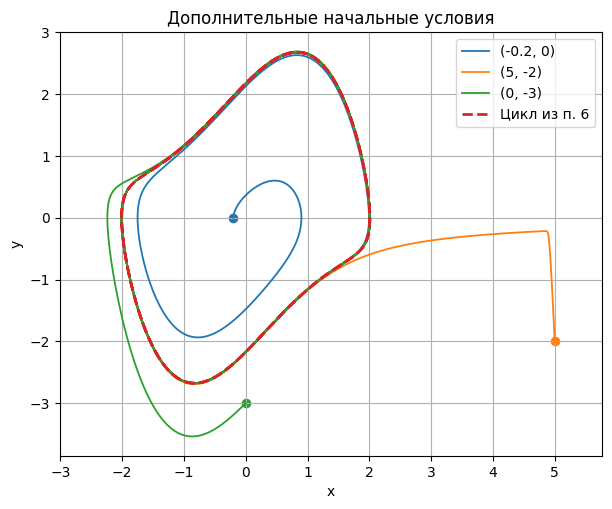

In [9]:
extra = [(-0.2, 0), (5, -2), (0, -3)]

plt.figure(figsize=(7, 5.5))
for a in extra:
    s = solve_ivp(vdp, (0, 45), a, args=(1,), t_eval=t,
                  rtol=1e-9, atol=1e-11)
    assert s.success
    plt.plot(s.y[0], s.y[1], label=str(a), linewidth=1.3)
    plt.scatter(a[0], a[1], s=35)
    print(a, '-> max |x| при t >= 30:',
          round(np.max(np.abs(s.y[0, s.t >= 30])), 4))

k = curves[0].t >= 30
plt.plot(curves[0].y[0, k], curves[0].y[1, k],
         linestyle='--', linewidth=2, label='Цикл из п. 6')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Дополнительные начальные условия')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

Новые решения тоже приближаются к той же кривой. Для этих начальных условий меняется в основном переходный участок, а при больших $t$ колебания уже почти одинаковые.